In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

SYMBOL = "AAPL"
TRADING_DAYS = 252

df = yf.Ticker(SYMBOL).history(
    period="2y",
    interval="1d",
    auto_adjust=True
)

if df.empty:
    raise ValueError("Market data is empty.")

df = df[["Open", "High", "Low", "Close", "Volume"]].copy()

df = df.sort_index()
df = df.loc[~df.index.duplicated(keep="last")]
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna()

df = df.loc[
    (df[["Open", "High", "Low", "Close"]] > 0).all(axis=1)
    & (df["Volume"] >= 0)
    & (df["High"] >= df[["Open", "Close", "Low"]].max(axis=1))
    & (df["Low"] <= df[["Open", "Close", "High"]].min(axis=1))
].copy()

if len(df) < 200:
    raise ValueError("Insufficient data for financial indicators.")

df["Return"] = df["Close"].pct_change(fill_method=None)

df.head()

,Open,High,Low,Close,Volume,Return
Date,,,,,,
2024-11-25 00:00:00-05:00,229.617926,231.393674,227.911614,231.016693,90152800,NaN
2024-11-26 00:00:00-05:00,231.473042,233.695221,231.473042,233.189270,45986200,0.009404
2024-11-27 00:00:00-05:00,232.603957,233.814249,231.949206,233.060287,33498400,-0.000553
2024-11-29 00:00:00-05:00,232.941244,235.917368,232.107933,235.441193,28481400,0.010216
2024-12-02 00:00:00-05:00,235.381699,238.873674,235.272574,237.683228,48137100,0.009523


In [2]:
df["SMA_20"] = df["Close"].rolling(window=20).mean()

df["SMA_50"] = df["Close"].rolling(window=50).mean()

df["SMA_200"] = df["Close"].rolling(window=200).mean()

df[["Close", "SMA_20", "SMA_50", "SMA_200"]].tail()

,Close,SMA_20,SMA_50,SMA_200
Date,,,,
2026-11-18 00:00:00-05:00,352.450012,347.489154,340.916439,302.079315
2026-11-19 00:00:00-05:00,349.209991,347.551872,341.374198,302.447715
2026-11-20 00:00:00-05:00,342.559998,347.306572,341.585044,302.785754
2026-11-23 00:00:00-05:00,349.079987,347.578127,341.910102,303.145382
2026-11-24 00:00:00-05:00,354.070007,347.939803,342.369733,303.546119


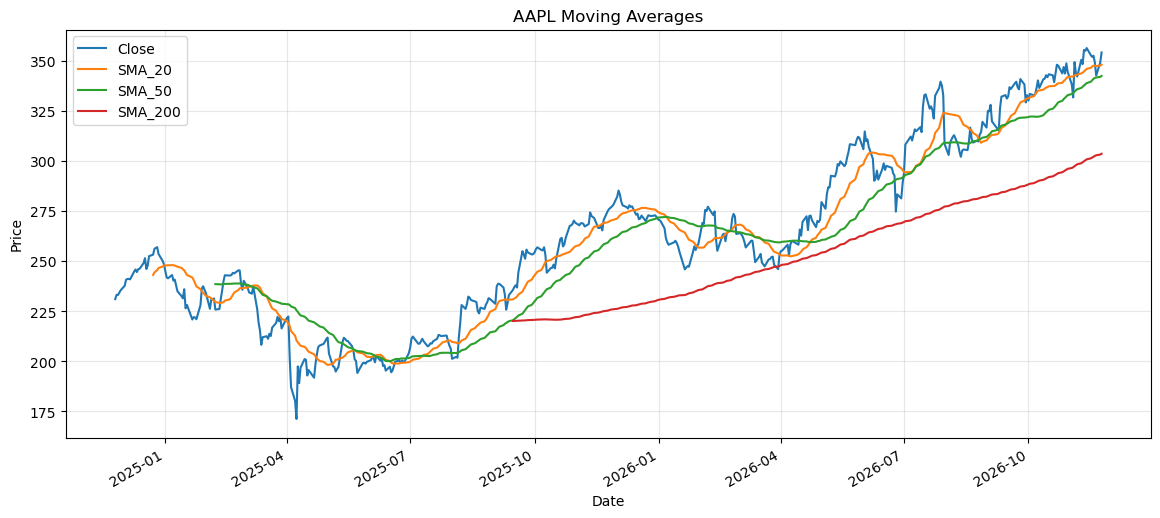

In [3]:
df[["Close", "SMA_20", "SMA_50", "SMA_200"]].plot(
    figsize=(14, 6)
)

plt.title(f"{SYMBOL} Moving Averages")
plt.ylabel("Price")
plt.grid(alpha=0.3)
plt.show()

In [4]:
df["EMA_12"] = df["Close"].ewm(
    span=12,
    adjust=False
).mean()

df["EMA_26"] = df["Close"].ewm(
    span=26,
    adjust=False
).mean()

df["EMA_20"] = df["Close"].ewm(
    span=20,
    adjust=False
).mean()

df[["Close", "EMA_12", "EMA_26", "EMA_20"]].tail()

,Close,EMA_12,EMA_26,EMA_20
Date,,,,
2026-11-18 00:00:00-05:00,352.450012,350.261954,346.270071,347.901046
2026-11-19 00:00:00-05:00,349.209991,350.100113,346.487843,348.025707
2026-11-20 00:00:00-05:00,342.559998,348.940095,346.196891,347.505163
2026-11-23 00:00:00-05:00,349.079987,348.961617,346.410454,347.655147
2026-11-24 00:00:00-05:00,354.070007,349.747523,346.977828,348.266086


In [5]:
def calculate_rsi(close, period=14):
    if len(close) <= period:
        raise ValueError("Insufficient data for RSI.")

    delta = close.diff()

    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)

    avg_gain = gain.copy() * np.nan
    avg_loss = loss.copy() * np.nan

    avg_gain.iloc[period] = gain.iloc[1:period + 1].mean()
    avg_loss.iloc[period] = loss.iloc[1:period + 1].mean()

    for i in range(period + 1, len(close)):
        avg_gain.iloc[i] = (
            avg_gain.iloc[i - 1] * (period - 1)
            + gain.iloc[i]
        ) / period

        avg_loss.iloc[i] = (
            avg_loss.iloc[i - 1] * (period - 1)
            + loss.iloc[i]
        ) / period

    rs = avg_gain / avg_loss

    rsi = 100 - (100 / (1 + rs))

    rsi = rsi.mask(
        (avg_gain == 0) & (avg_loss == 0),
        50
    )

    return rsi


df["RSI_14"] = calculate_rsi(df["Close"])

df[["Close", "RSI_14"]].tail()

,Close,RSI_14
Date,,
2026-11-18 00:00:00-05:00,352.450012,56.776777
2026-11-19 00:00:00-05:00,349.209991,53.156032
2026-11-20 00:00:00-05:00,342.559998,46.589004
2026-11-23 00:00:00-05:00,349.079987,52.752228
2026-11-24 00:00:00-05:00,354.070007,56.855608


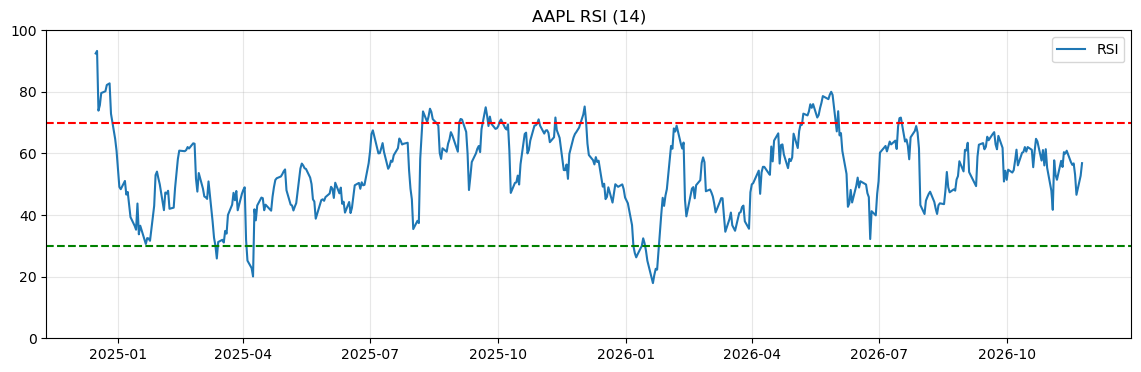

In [6]:
plt.figure(figsize=(14, 4))

plt.plot(df.index, df["RSI_14"], label="RSI")

plt.axhline(70, color="red", linestyle="--")
plt.axhline(30, color="green", linestyle="--")

plt.ylim(0, 100)
plt.title(f"{SYMBOL} RSI (14)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [7]:
df["MACD"] = df["EMA_12"] - df["EMA_26"]

df["MACD_Signal"] = df["MACD"].ewm(
    span=9,
    adjust=False
).mean()

df["MACD_Histogram"] = (
    df["MACD"] - df["MACD_Signal"]
)

df[["MACD", "MACD_Signal", "MACD_Histogram"]].tail()

,MACD,MACD_Signal,MACD_Histogram
Date,,,
2026-11-18 00:00:00-05:00,3.991883,3.675518,0.316364
2026-11-19 00:00:00-05:00,3.612270,3.662869,-0.050598
2026-11-20 00:00:00-05:00,2.743204,3.478936,-0.735732
2026-11-23 00:00:00-05:00,2.551163,3.293381,-0.742218
2026-11-24 00:00:00-05:00,2.769695,3.188644,-0.418949


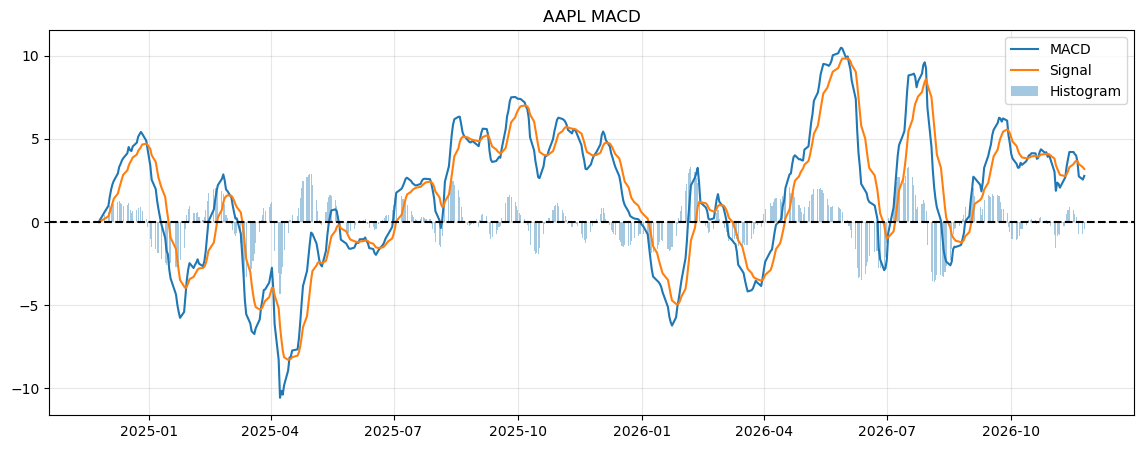

In [8]:
plt.figure(figsize=(14, 5))

plt.plot(df.index, df["MACD"], label="MACD")

plt.plot(
    df.index,
    df["MACD_Signal"],
    label="Signal"
)

plt.bar(
    df.index,
    df["MACD_Histogram"],
    alpha=0.4,
    label="Histogram"
)

plt.axhline(0, color="black", linestyle="--")

plt.title(f"{SYMBOL} MACD")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [9]:
df["BB_Middle"] = df["Close"].rolling(20).mean()

df["BB_STD"] = df["Close"].rolling(20).std(ddof=0)

df["BB_Upper"] = (
    df["BB_Middle"] + 2 * df["BB_STD"]
)

df["BB_Lower"] = (
    df["BB_Middle"] - 2 * df["BB_STD"]
)

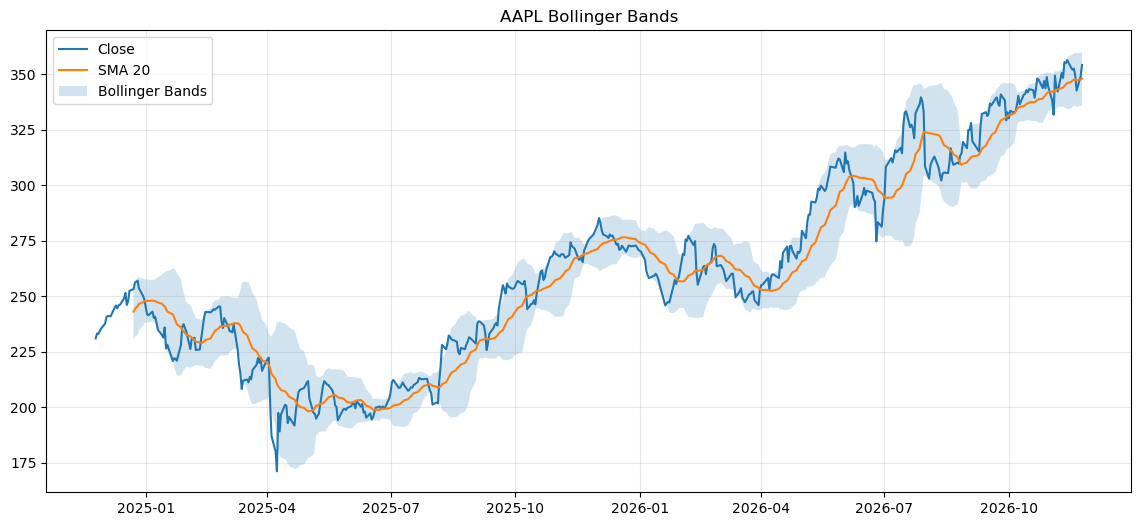

In [10]:
plt.figure(figsize=(14, 6))

plt.plot(df.index, df["Close"], label="Close")

plt.plot(df.index, df["BB_Middle"], label="SMA 20")

plt.fill_between(
    df.index,
    df["BB_Lower"],
    df["BB_Upper"],
    alpha=0.2,
    label="Bollinger Bands"
)

plt.title(f"{SYMBOL} Bollinger Bands")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [11]:
returns = df["Return"].dropna()

daily_volatility = returns.std()

annual_volatility = (
    daily_volatility * np.sqrt(TRADING_DAYS)
)

df["Rolling_Volatility_20"] = (
    df["Return"].rolling(20).std()
    * np.sqrt(TRADING_DAYS)
)

print(f"Daily Volatility: {daily_volatility:.2%}")
print(f"Annualized Volatility: {annual_volatility:.2%}")

Daily Volatility: 1.83%
Annualized Volatility: 29.06%


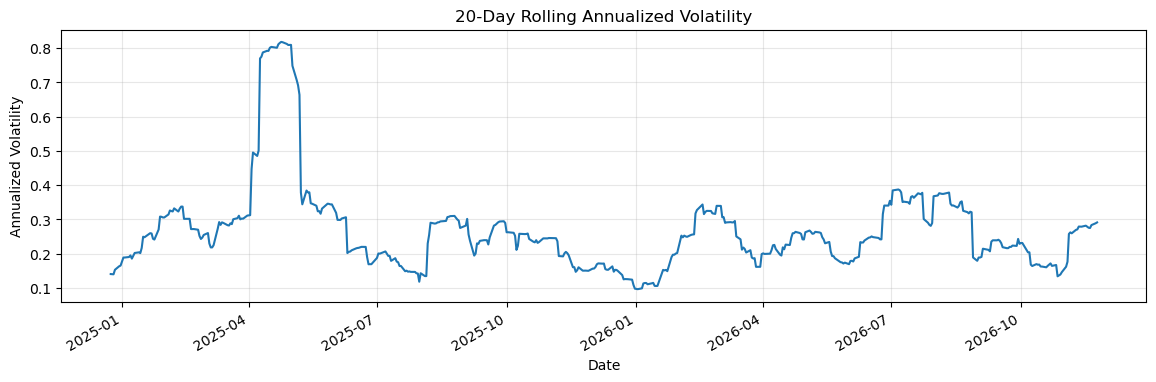

In [12]:
df["Rolling_Volatility_20"].plot(
    figsize=(14, 4),
    title="20-Day Rolling Annualized Volatility"
)

plt.ylabel("Annualized Volatility")
plt.grid(alpha=0.3)
plt.show()

In [13]:
annualized_mean_return = (
    returns.mean() * TRADING_DAYS
)

total_return = (
    df["Close"].iloc[-1] / df["Close"].iloc[0] - 1
)

years = (
    df.index[-1] - df.index[0]
).total_seconds() / (365.25 * 24 * 60 * 60)

cagr = (
    (df["Close"].iloc[-1] / df["Close"].iloc[0])
    ** (1 / years) - 1
)

print(f"Total Return: {total_return:.2%}")
print(f"Annualized Mean Return: {annualized_mean_return:.2%}")
print(f"CAGR: {cagr:.2%}")

Total Return: 53.27%
Annualized Mean Return: 25.72%
CAGR: 23.86%


In [14]:
RISK_FREE_RATE = 0.04

daily_risk_free_rate = (
    (1 + RISK_FREE_RATE) ** (1 / TRADING_DAYS) - 1
)

excess_returns = returns - daily_risk_free_rate

excess_std = excess_returns.std()

sharpe_ratio = (
    excess_returns.mean() / excess_std
    * np.sqrt(TRADING_DAYS)
    if excess_std > 0
    else np.nan
)

print(f"Sharpe Ratio: {sharpe_ratio:.4f}")

Sharpe Ratio: 0.7499


In [15]:
df["Running_Peak"] = df["Close"].cummax()

df["Drawdown"] = (
    df["Close"] / df["Running_Peak"] - 1
)

max_drawdown = df["Drawdown"].min()

print(f"Maximum Drawdown: {max_drawdown:.2%}")

Maximum Drawdown: -33.36%


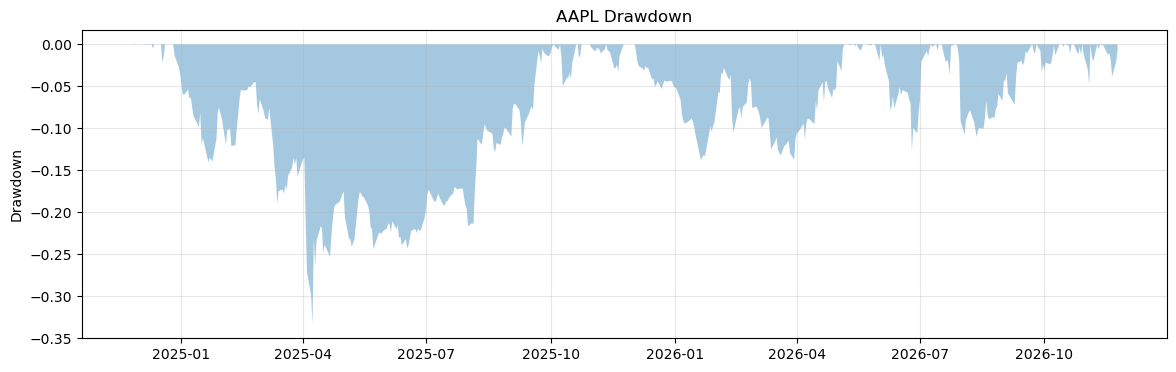

In [16]:
plt.figure(figsize=(14, 4))

plt.fill_between(
    df.index,
    df["Drawdown"],
    0,
    alpha=0.4
)

plt.title(f"{SYMBOL} Drawdown")
plt.ylabel("Drawdown")
plt.grid(alpha=0.3)
plt.show()

In [17]:
CONFIDENCE_LEVEL = 0.95

losses = -returns

var_95 = losses.quantile(CONFIDENCE_LEVEL)

es_95 = losses[
    losses >= var_95
].mean()

print(f"Historical Daily VaR (95%): {var_95:.2%}")
print(f"Historical Daily ES (95%): {es_95:.2%}")

Historical Daily VaR (95%): 2.66%
Historical Daily ES (95%): 4.23%


In [18]:
financial_report = {
    "symbol": SYMBOL,
    "data_source": "Yahoo Finance via yfinance",
    "price_type": "adjusted",
    "start_date": str(df.index[0].date()),
    "end_date": str(df.index[-1].date()),
    "observations": len(df),

    "price": {
        "latest_close": float(df["Close"].iloc[-1]),
        "sma_20": float(df["SMA_20"].iloc[-1]),
        "sma_50": float(df["SMA_50"].iloc[-1]),
        "sma_200": float(df["SMA_200"].iloc[-1])
    },

    "momentum": {
        "rsi_14": float(df["RSI_14"].iloc[-1]),
        "macd": float(df["MACD"].iloc[-1]),
        "macd_signal": float(df["MACD_Signal"].iloc[-1])
    },

    "performance": {
        "total_return": float(total_return),
        "annualized_mean_return": float(annualized_mean_return),
        "cagr": float(cagr),
        "sharpe_ratio": float(sharpe_ratio)
    },

    "risk": {
        "annualized_volatility": float(annual_volatility),
        "maximum_drawdown": float(max_drawdown),
        "daily_var_95": float(var_95),
        "daily_es_95": float(es_95)
    },

    "assumptions": {
        "trading_days_per_year": TRADING_DAYS,
        "annual_risk_free_rate": RISK_FREE_RATE,
        "confidence_level": CONFIDENCE_LEVEL
    }
}

financial_report

{'symbol': 'AAPL',
 'data_source': 'Yahoo Finance via yfinance',
 'price_type': 'adjusted',
 'start_date': '2024-11-25',
 'end_date': '2026-11-24',
 'observations': 501,
 'price': {'latest_close': 354.07000732421875,
  'sma_20': 347.9398025512695,
  'sma_50': 342.3697332763672,
  'sma_200': 303.5461187744141},
 'momentum': {'rsi_14': 56.855607937534344,
  'macd': 2.769694978966811,
  'macd_signal': 3.188643898296876},
 'performance': {'total_return': 0.5326598374759164,
  'annualized_mean_return': 0.25717848669507315,
  'cagr': 0.23855037854019256,
  'sharpe_ratio': 0.7499215704267111},
 'risk': {'annualized_volatility': 0.2906366877107656,
  'maximum_drawdown': -0.3336051459278526,
  'daily_var_95': 0.026581187328655904,
  'daily_es_95': 0.04232083224863344},
 'assumptions': {'trading_days_per_year': 252,
  'annual_risk_free_rate': 0.04,
  'confidence_level': 0.95}}

In [19]:
import json


def sanitize_json(value):
    if isinstance(value, dict):
        return {
            key: sanitize_json(item)
            for key, item in value.items()
        }

    if isinstance(value, float) and not np.isfinite(value):
        return None

    return value


financial_report = sanitize_json(financial_report)

report_json = json.dumps(
    financial_report,
    indent=4,
    allow_nan=False
)

print(report_json)

{
    "symbol": "AAPL",
    "data_source": "Yahoo Finance via yfinance",
    "price_type": "adjusted",
    "start_date": "2024-11-25",
    "end_date": "2026-11-24",
    "observations": 501,
    "price": {
        "latest_close": 354.07000732421875,
        "sma_20": 347.9398025512695,
        "sma_50": 342.3697332763672,
        "sma_200": 303.5461187744141
    },
    "momentum": {
        "rsi_14": 56.855607937534344,
        "macd": 2.769694978966811,
        "macd_signal": 3.188643898296876
    },
    "performance": {
        "total_return": 0.5326598374759164,
        "annualized_mean_return": 0.25717848669507315,
        "cagr": 0.23855037854019256,
        "sharpe_ratio": 0.7499215704267111
    },
    "risk": {
        "annualized_volatility": 0.2906366877107656,
        "maximum_drawdown": -0.3336051459278526,
        "daily_var_95": 0.026581187328655904,
        "daily_es_95": 0.04232083224863344
    },
    "assumptions": {
        "trading_days_per_year": 252,
        "annual_